# Reingreso a <30 días en pacientes diabéticos: la cadena completa

**Pregunta.** ¿Reingresa el paciente en menos de 30 días tras el alta? El gestor de calidad
usa la respuesta para decidir a quién hacer seguimiento con un presupuesto (top 5/10/20 %).

**Qué muestra este notebook.** La cadena de punta a punta: datos y preprocesado → modelo con su
guardarraíl → explicaciones (global, sanity checks y local) → corrección del target → equidad →
lectura de la consulta a test. Lo rápido se recalcula aquí. Lo lento (bootstrap de 2.000
réplicas, CV, DiCE, ablación) se **lee de `reports/`**, y cada sección dice qué script lo escribe.

**Cómo ejecutarlo.** `pip install -r requirements.txt` (incluye jupyter). Se puede abrir desde
`notebooks/` o desde la raíz del proyecto: el notebook localiza `src/` solo.

**Reglas de lectura.**
- **Test no se recalcula aquí.** Sus cifras se leen de los CSV de la consulta única
  (`src/phase4_test_final.py`). No se toma ninguna decisión con ellas.
- **Los guardarraíles avisan, no detienen.** Si el número de árboles o el PR-AUC no coinciden
  con lo documentado (por ejemplo, por una versión distinta de LightGBM), aparece un aviso con
  esperado frente a obtenido y el notebook sigue. Los scripts de `src/` sí usan `assert`.
- Cada cifra lleva su CSV y su denominador. El razonamiento de cada decisión está en `CLAUDE.md`.

## Hallazgos principales

Resumen de los cuatro resultados, con lo que **sí** replica y lo que **no**. Cada cifra está en la
sección indicada y sale de un CSV de `reports/`.

1. **La etiqueta contiene una fuga (Sección 5).** En los destinos 22 (rehabilitación) y 5 (otra
   institución), buena parte de los "reingresos" son continuaciones de cuidados (V57) o ingresos
   programados: el 68,2 % de los reingresos visibles del destino 22 cumple eso. El encuentro
   siguiente también es menos visible en esos destinos. Es un defecto de construcción de la
   etiqueta, no del modelo.
2. **Los sanity checks no lo detectan (Secciones 4 y 10).** Las explicaciones son estables entre
   folds y pasan sus criterios prerregistrados, porque todos los folds comparten la misma etiqueta
   contaminada. **Estabilidad no es validez.**
3. **La ventaja de A sobre B se invierte al corregir la etiqueta (Secciones 6 y 7).** En val, la
   brecha A − B pasa de +4,99 a −5,51 puntos, y el contraste emparejado da −10,50 [−13,94; −7,13].
   **Lo que no replica en test:** (a) el punto de partida: en el paso (1) de test el IC95 es
   [−7,45; +2,41], que incluye el cero, así que A y B no se distinguen; (b) el criterio formal
   `delta_A − delta_B` no sale significativo en test (+0,64 [−4,55; +5,64] con el modelo 3a;
   +3,45 [−2,90; +9,28] con el entregable). **Lo que sí replica:** el cambio de la brecha entre los
   pasos (2) y (1), −4,63 [−7,57; −1,65], con menos de la mitad de la magnitud de val.
4. **Validez y equidad van en sentidos opuestos (Sección 8).** Corregir la etiqueta no baja el
   rendimiento global (lift medio en CV 1,9914 con la etiqueta vieja y 1,9878 con la nueva), pero sí
   cambia a quién se le hace seguimiento: SP pasa de 0,83 a 0,39 y Missing de 1,45 a 2,07, frente a MC.
   Quitar `payer_code` arregla Missing (0,96) pero no SP (0,44).

In [1]:
import sys
import time
from pathlib import Path

T0 = time.time()

# Localiza la raíz del proyecto tanto si el notebook se abre desde notebooks/ como desde la raíz.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))  # los módulos de src/ se importan igual que en los scripts

import lightgbm as lgb
import numpy as np
import pandas as pd
import shap
from IPython.display import Image, Markdown, display
from sklearn.metrics import average_precision_score, roc_auc_score

import data as D
import phase4_correction as PC
import preprocessing as P
import target_correction as TC
import train_lgbm as TL
from evaluate_test import CHOSEN  # num_leaves=31, min_child_samples=20 (Fase 2)

REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

AVISOS = []


def comprueba(nombre, ok, detalle):
    """Imprime OK o un aviso visible. NUNCA detiene el notebook."""
    if ok:
        print(f"[OK] {nombre}: {detalle}")
    else:
        msg = (f"{nombre}: {detalle}. Puede deberse a una versión distinta de una librería "
               "(ver requirements.txt). La ejecución continúa; lee esta sección con cautela.")
        AVISOS.append(msg)
        print(f"[AVISO] {msg}")
        display(Markdown(f"> ⚠️ **AVISO** — {msg}"))


def guardarrail(nombre, esperado, obtenido, tol=0.0):
    ok = (abs(obtenido - esperado) <= tol) if tol else (obtenido == esperado)
    comprueba(nombre, ok, f"esperado {esperado}, obtenido {obtenido}")


def fmt_int(n):
    return f"{int(n):,}".replace(",", ".")


print("Entorno listo. Carpeta del proyecto:", ROOT.name)

Entorno listo. Carpeta del proyecto: final-project


## 1. Datos y preprocesado

`src/data.py` descarga el dataset (UCI 296) y lo limpia: se quitan los encuentros con alta por
fallecimiento u hospicio y los de género inválido, siguiendo a Strack et al. (2014). El target es
reingreso en menos de 30 días. El split es 60/20/20 **agrupado por `patient_nbr`**, para que un
mismo paciente no aparezca en dos particiones. Ese agrupamiento importa: el 23,5 % de los pacientes
tiene varios encuentros.

In [2]:
train, val, test = P.load_model_data()  # test se carga para el split, pero no se usa en este notebook
n_limpio = len(train) + len(val) + len(test)
guardarrail("encuentros tras la limpieza", 99340, n_limpio)

tabla = pd.DataFrame({
    "split": ["train", "val", "test"],
    "filas (denominador)": [len(train), len(val), len(test)],
    "reingresos <30 d (target original)": [int(train[D.TARGET].sum()), int(val[D.TARGET].sum()), np.nan],
})
tabla["% reingreso (sobre filas)"] = (100 * tabla["reingresos <30 d (target original)"]
                                      / tabla["filas (denominador)"]).round(2)
print("Test: no se calcula su prevalencia ni ninguna métrica en este notebook.")
tabla

[OK] encuentros tras la limpieza: esperado 99340, obtenido 99340
Test: no se calcula su prevalencia ni ninguna métrica en este notebook.


,split,filas (denominador),reingresos <30 d (target original),% reingreso (sobre filas)
0,train,59605,6788.0,11.39
1,val,19868,2263.0,11.39
2,test,19867,NaN,NaN


## 2. Modelo: LightGBM con guardarraíl

LightGBM con categóricas nativas, `num_leaves=31`, `min_child_samples=20` y `learning_rate=0.03`.
El número de árboles lo decide el early stopping sobre el PR-AUC de **val**, no se fija a mano.

**Guardarraíl:** el modelo reentrenado debe tener **122 árboles** y **PR-AUC 0,2308** en val, los
de la Fase 2. Si no coinciden, el aviso lo dice y el notebook sigue.

In [3]:
Xtr, ytr = P.split_xy(train)
Xva, yva = P.split_xy(val)
Ltr, Lva = P.to_lgbm_frames(train, val)  # categóricas como 'category' para LightGBM

old = TL.fit_lgbm(Ltr, ytr, Lva, yva, **CHOSEN)
trees_old = old.best_iteration_
pr_old = old.best_score_["val"]["average_precision"]
guardarrail("árboles del modelo original", 122, trees_old)
guardarrail("PR-AUC val del modelo original", 0.2308, round(pr_old, 4), tol=5e-5)

# Métricas de VAL del modelo original, con el target original. Denominador: 19.868 filas de val.
p_old_val = old.predict_proba(Lva)[:, 1]
prev_val = yva.mean()
pr_val = average_precision_score(yva, p_old_val)
metricas = pd.DataFrame([{
    "modelo": "original (target original), val",
    "n": len(yva),
    "prevalencia_%": 100 * prev_val,
    "ROC-AUC": roc_auc_score(yva, p_old_val),
    "PR-AUC": pr_val,
    "lift (PR-AUC / prevalencia)": pr_val / prev_val,
}])
display(metricas.round(4))

# Contraste con el CSV publicado: misma cifra, otra vía de cálculo.
csv_val = pd.read_csv(REPORTS / "phase4_val_metrics.csv")
pr_csv = float(csv_val.loc[csv_val["caso"] == "(1) viejo/vieja", "pr_auc"].iloc[0])
comprueba("PR-AUC val coincide con reports/phase4_val_metrics.csv",
          abs(pr_val - pr_csv) < 1e-9, f"{pr_val:.6f} frente a {pr_csv:.6f}")

[OK] árboles del modelo original: esperado 122, obtenido 122
[OK] PR-AUC val del modelo original: esperado 0.2308, obtenido 0.2308


,modelo,n,prevalencia_%,ROC-AUC,PR-AUC,lift (PR-AUC / prevalencia)
0,"original (target original), val",19868,11.3902,0.6772,0.2308,2.0261


[OK] PR-AUC val coincide con reports/phase4_val_metrics.csv: 0.230776 frente a 0.230776


## 3. Explicación global: SHAP sobre val

TreeSHAP reparte la predicción entre las 44 variables originales, en log-odds. Se usa **val** y no
test, porque de estas explicaciones salen decisiones (Sección 6). Como comprobación, el valor base
más la suma de contribuciones debe reproducir la salida del modelo, y debe coincidir con
`pred_contrib` de LightGBM.

Limitación que hay que tener presente: `tree_path_dependent` sigue las ramas de los árboles, así
que reparte crédito según las correlaciones con las que se entrenó el modelo.

C:\venvs\xai-final\Lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


[OK] aditividad: base + suma = log-odds: error máximo 7.99e-15
[OK] coincide con pred_contrib de LightGBM: diferencia máxima 0.00e+00
Media de |SHAP| (log-odds) sobre val, n = 19.868 filas. Top 10:
number_inpatient            0.2888
discharge_disposition_id    0.2043
diag_1_group                0.0633
payer_code                  0.0477
medical_specialty           0.0374
age                         0.0373
number_diagnoses            0.0363
diabetesMed                 0.0357
number_emergency            0.0350
time_in_hospital            0.0318


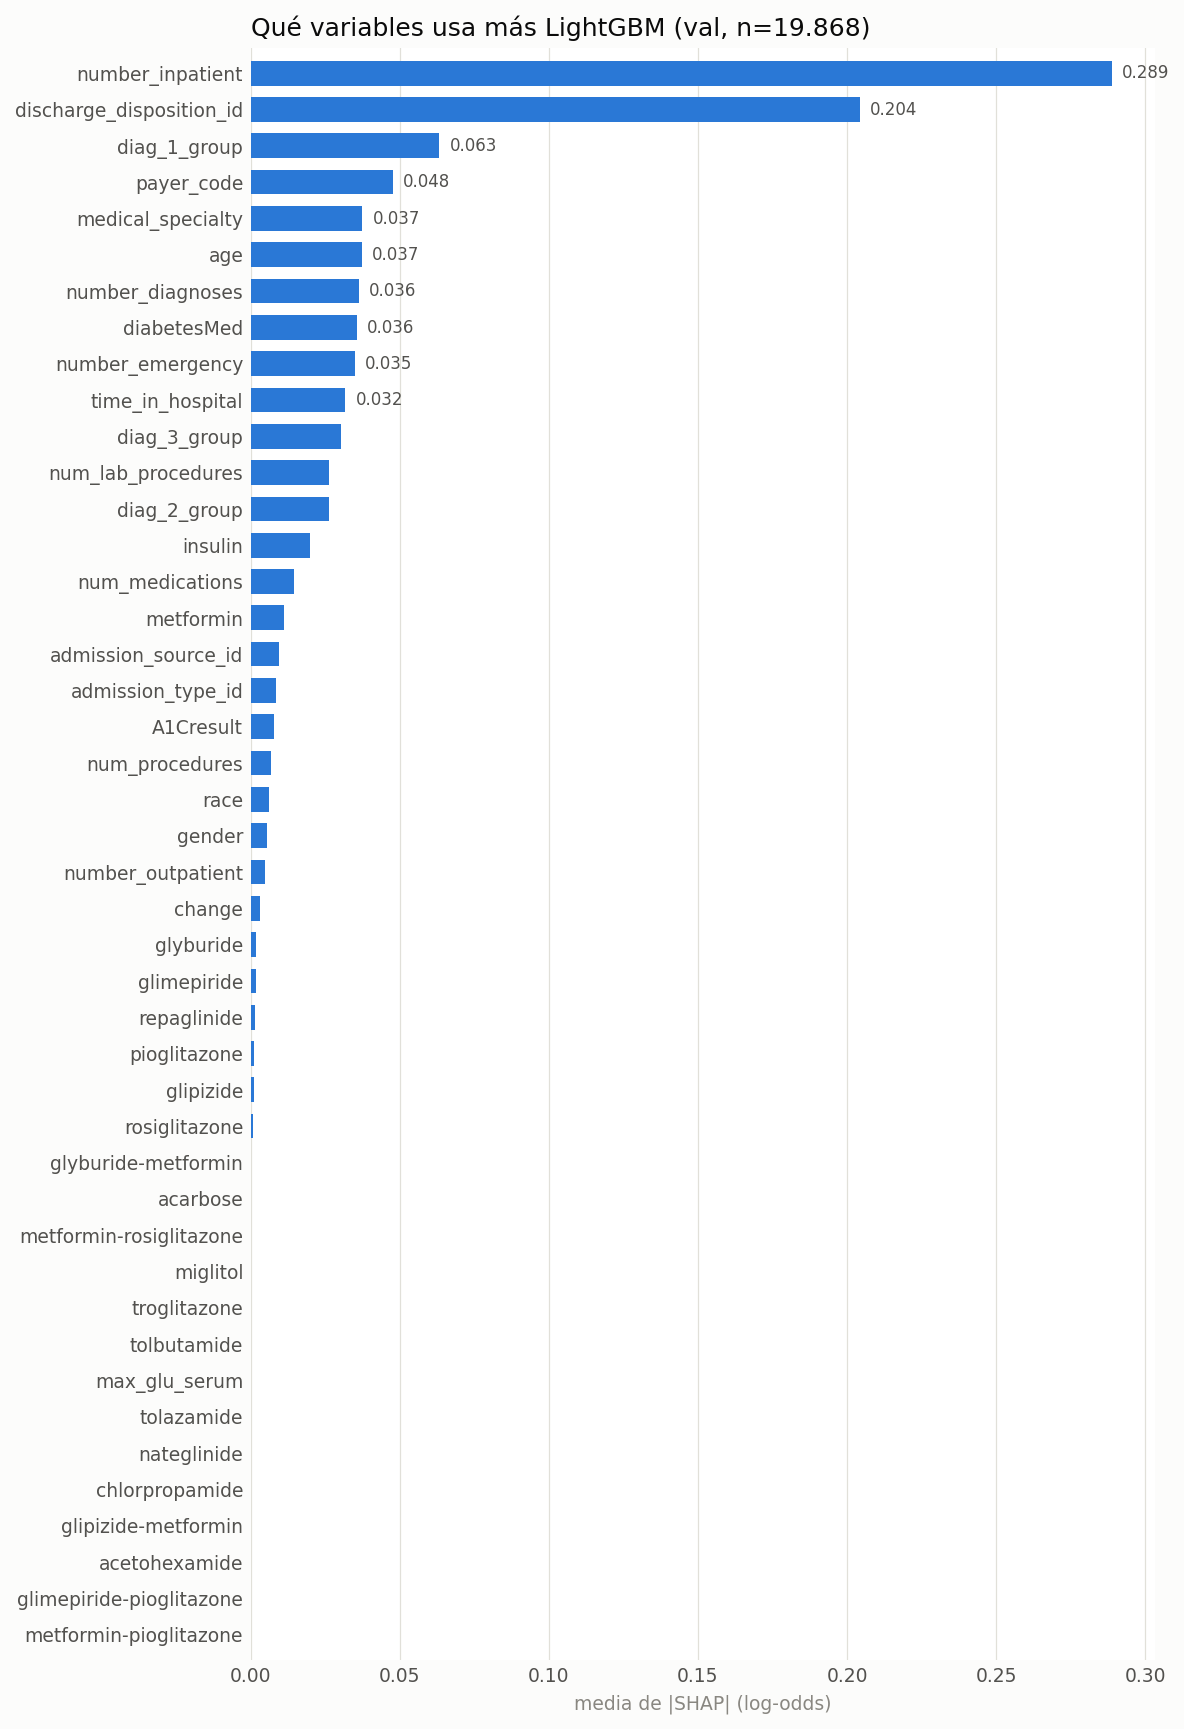

In [4]:
booster = lgb.Booster(model_str=old.booster_.model_to_string(num_iteration=trees_old))
explainer = shap.TreeExplainer(booster, feature_perturbation="tree_path_dependent")
sv = explainer.shap_values(Lva)
if isinstance(sv, list):  # algunas versiones devuelven una matriz por clase
    sv = sv[1]
base = float(np.ravel(explainer.expected_value)[-1])

err_aditiva = float(np.abs(base + sv.sum(axis=1) - booster.predict(Lva, raw_score=True)).max())
err_nativa = float(np.abs(sv - booster.predict(Lva, pred_contrib=True)[:, :-1]).max())
comprueba("aditividad: base + suma = log-odds", err_aditiva < 1e-6, f"error máximo {err_aditiva:.2e}")
comprueba("coincide con pred_contrib de LightGBM", err_nativa < 1e-8, f"diferencia máxima {err_nativa:.2e}")

imp = pd.Series(np.abs(sv).mean(axis=0), index=Lva.columns).sort_values(ascending=False)
print(f"Media de |SHAP| (log-odds) sobre val, n = {fmt_int(len(Lva))} filas. Top 10:")
print(imp.head(10).round(4).to_string())
display(Image(FIG / "shap_global_bar.png", width=720))

El ranking global coincide con la importancia por permutación de la Fase 3a en los dos primeros
puestos: `number_inpatient` y `discharge_disposition_id`. A partir del tercero el orden entre
métodos no es fiable, porque el ruido de la permutación es del mismo orden que la señal
(`reports/xai_global_comparison.csv`).

## 4. Sanity checks y explicación local (leídos de `reports/`)

Estas partes necesitan muchas ejecuciones y se leen de disco. Los scripts que las escriben son
`src/xai_sanity.py` (Fase 3b) y `src/xai_local.py` (Fase 3d).

- **Sanity checks.** Solo 13 de 44 variables superan las sondas de ruido en las 10 semillas. Las
  demás **no se interpretan**, según la regla fijada antes de ver resultados.
- **Local.** Los 11 casos se fijaron con regla y semilla antes de mirar sus explicaciones. Son de
  tres tipos: `perfil_alto_*` (centroides del top 10 %), pares contrastivos y casos de referencia.

Variables que superan las sondas de ruido en 10/10 semillas: 13 de 44
Fármacos y race/gender no superan las sondas: A1Cresult, race, gender, insulin
[OK] number_inpatient en el top-3 local (de 11 casos): esperado 11, obtenido 11
[OK] discharge_disposition_id en el top-3 local (de 11 casos): esperado 9, obtenido 9


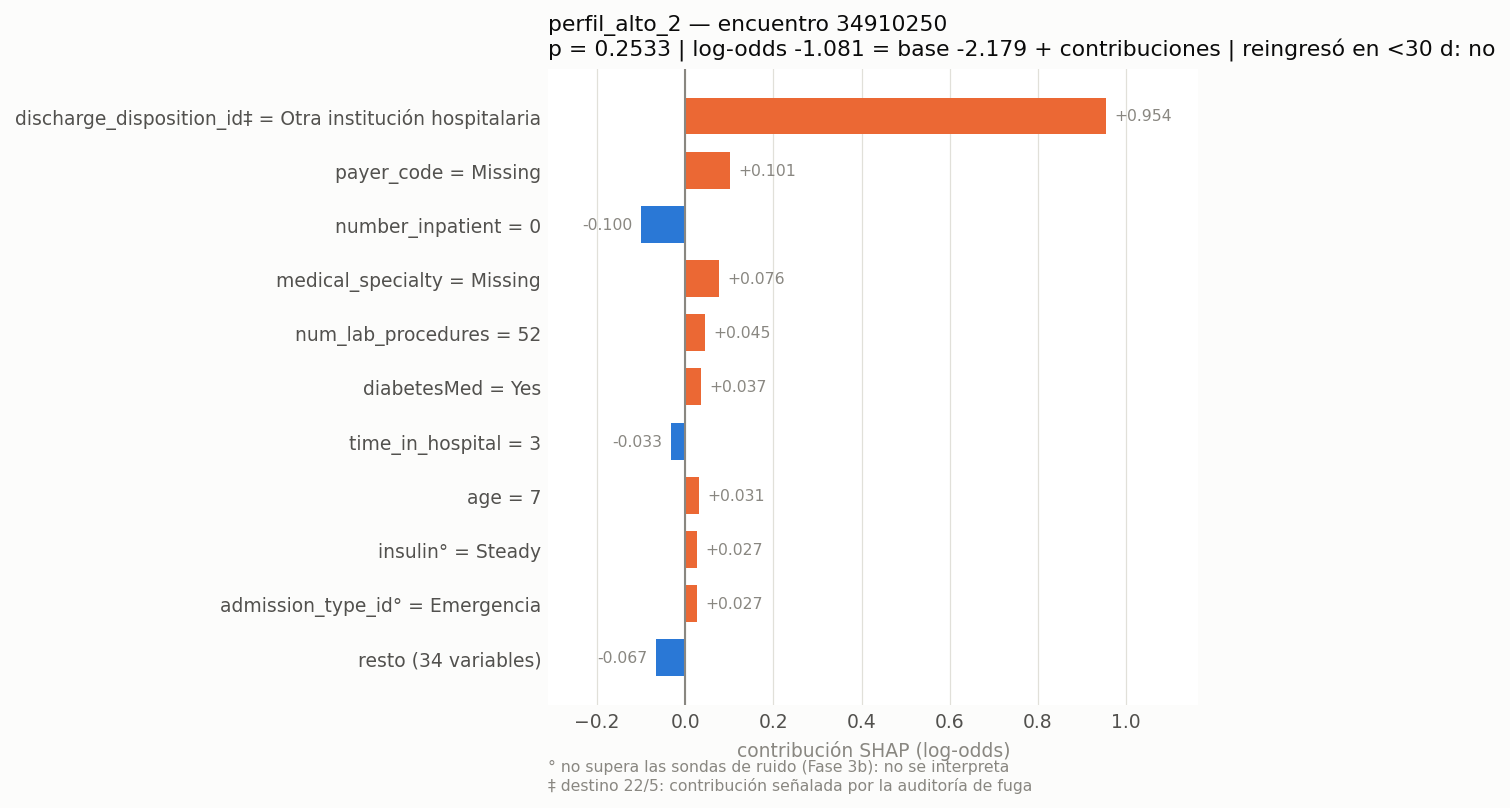

Caso con destino 22/5: el destino es la contribución mayor, pero se marca como fuga de la etiqueta y no se lee como riesgo (ver Sección 5).


In [5]:
probes = pd.read_csv(REPORTS / "xai_sanity_noise_probes.csv", index_col=0)
n_ok = int((probes["gana_a_sonda"] == 10).sum())
print(f"Variables que superan las sondas de ruido en 10/10 semillas: {n_ok} de {len(probes)}")
print("Fármacos y race/gender no superan las sondas:",
      ", ".join(v for v in ["A1Cresult", "race", "gender", "insulin"] if probes.loc[v, "gana_a_sonda"] < 10))

loc = pd.read_csv(REPORTS / "xai_local_top_features.csv")
n_casos = loc["caso"].nunique()
top3 = loc[loc["rank_local"] <= 3]
for var, esperado in [("number_inpatient", 11), ("discharge_disposition_id", 9)]:
    n = top3.loc[top3["variable"] == var, "caso"].nunique()
    guardarrail(f"{var} en el top-3 local (de {n_casos} casos)", esperado, n)

display(Image(FIG / "shap_local_perfil_alto_2.png", width=760))
print("Caso con destino 22/5: el destino es la contribución mayor, pero se marca como fuga de la "
      "etiqueta y no se lee como riesgo (ver Sección 5).")

## 5. Acción 1: la auditoría del destino al alta

El target cuenta **cualquier** reingreso en menos de 30 días, no solo los no planificados. Hay dos
problemas:

1. En los destinos **22** (rehabilitación) y **5** (otra institución), buena parte de los
   "reingresos" son continuaciones de cuidados (diagnóstico V57) o ingresos programados.
2. En esos mismos destinos el encuentro siguiente es **menos visible**: el 36 % y el 38 % de sus
   positivos no tiene encuentro posterior registrado, frente al 27 % de las altas a casa.

Los porcentajes sobre "visibles" y sobre el total tienen denominadores distintos: se indican en
cada columna.

In [6]:
glob = pd.read_csv(REPORTS / "audit_discharge_global.csv").iloc[0]
print(f"Train+val, global: {fmt_int(glob.n_visibles)} de {fmt_int(glob.n_lt30)} reingresos <30 d "
      f"tienen encuentro posterior visible ({glob.pct_sin_visible:.2f} % sin visible). "
      f"De los {fmt_int(glob.n_visibles)} visibles, {glob.pct_V57_o_prog:.2f} % son V57 o programados.")

leak = pd.read_csv(REPORTS / "audit_discharge_leakage.csv", index_col=0)
cols = ["n_lt30", "n_visibles", "pct_V57", "pct_programado", "pct_V57_o_prog",
        "tasa_sin_V57_o_prog", "shap_medio_val"]
print("Por destino al alta (train+val). Porcentajes sobre n_visibles de cada fila:")
leak.index = leak.index.astype(str)  # el índice es texto ('22', 'Unknown', ...)
leak.loc[["1", "3", "5", "22"], cols].round(2)

Train+val, global: 6.503 de 9.051 reingresos <30 d tienen encuentro posterior visible (28.15 % sin visible). De los 6.503 visibles, 19.85 % son V57 o programados.
Por destino al alta (train+val). Porcentajes sobre n_visibles de cada fila:


,n_lt30,n_visibles,pct_V57,pct_programado,pct_V57_o_prog,tasa_sin_V57_o_prog,shap_medio_val
1,4481.0,3258.0,0.61,16.97,17.28,8.12,-0.17
3,1635.0,1102.0,5.08,12.52,16.52,13.07,0.31
5,201.0,125.0,32.80,39.20,55.20,13.91,0.78
22,442.0,283.0,57.24,59.01,68.20,15.64,1.06


## 6. Acción 2: corregir el target y medir la predicción

Se reetiqueta a 0 cada reingreso <30 días cuyo encuentro siguiente es V57 o programado. Solo se
puede hacer donde el encuentro siguiente es visible. El split **no cambia**: se calcula con el
target original y el reetiquetado va después, porque si cambiara el split, las cifras antes y
después no serían comparables. Sobre test solo se aplica la regla, para contar filas.

In [7]:
splits = {"train": train, "val": val, "test": test}
flags = TC.planned_flags()
TC.assert_next_within_split(splits, flags)  # integridad de datos: el encuentro siguiente nunca cae en otro split

cambios = TC.changed_counts(splits, flags)
print("Filas que pasan de 1 a 0 (solo el conteo; test no se puntúa):")
display(cambios[["split", "n", "filas_cambiadas"]])

ytr_new = TC.relabel(train, flags).to_numpy()
yva_new = TC.relabel(val, flags).to_numpy()

new = TL.fit_lgbm(Ltr, ytr_new, Lva, yva_new, **CHOSEN)
guardarrail("árboles del modelo corregido CON payer_code", 183, new.best_iteration_)
guardarrail("PR-AUC val del modelo corregido CON payer_code", 0.1893,
            round(new.best_score_["val"]["average_precision"], 4), tol=5e-5)

Filas que pasan de 1 a 0 (solo el conteo; test no se puntúa):


,split,n,filas_cambiadas
0,train,59605,971
1,val,19868,320
2,test,19867,307


[OK] árboles del modelo corregido CON payer_code: esperado 183, obtenido 183
[OK] PR-AUC val del modelo corregido CON payer_code: esperado 0.1893, obtenido 0.1893


**Validez global, en CV.** Antes de leer la brecha conviene saber si la corrección cambió el
rendimiento global. En CV agrupada de 5 folds dentro de train, con los mismos 122 árboles en ambas
etiquetas, el lift medio casi no se mueve: la contaminación no sostenía el rendimiento global, sino
la ventaja concreta en el grupo A.

In [8]:
cv = pd.read_csv(REPORTS / "phase4_cv_lift.csv")
resumen = cv.groupby("etiqueta")["lift"].agg(["mean", "std", "count"])
print("Lift en CV agrupada, 5 folds dentro de train (n_estimators fijo a 122 en ambas etiquetas):")
display(resumen.round(4))
guardarrail("lift medio CV, etiqueta vieja", 1.9914, round(resumen.loc["vieja", "mean"], 4), tol=1e-4)
guardarrail("lift medio CV, etiqueta nueva", 1.9878, round(resumen.loc["nueva", "mean"], 4), tol=1e-4)

Lift en CV agrupada, 5 folds dentro de train (n_estimators fijo a 122 en ambas etiquetas):


,mean,std,count
etiqueta,,,
nueva,1.9878,0.0575,5
vieja,1.9914,0.0200,5


[OK] lift medio CV, etiqueta vieja: esperado 1.9914, obtenido 1.9914
[OK] lift medio CV, etiqueta nueva: esperado 1.9878, obtenido 1.9878


**Los tres pasos de la predicción prerregistrada.** Se toma el top 10 % de val en cada paso, con el
corte recalculado sobre sus propias puntuaciones, y se parte en dos subgrupos:

- **A** = top 10 % con `number_inpatient == 0` (la regla simple no los marca).
- **B** = top 10 % con `number_inpatient >= 1`.

Los pasos son: (1) modelo viejo con etiqueta vieja; (2) el mismo modelo con etiqueta nueva; (3)
modelo nuevo con etiqueta nueva. Entre (1) y (2) solo cambia la verdad contra la que se puntúa.

In [9]:
p_old = pd.Series(old.predict_proba(Lva)[:, 1], index=Xva.index)
p_new = pd.Series(new.predict_proba(Lva)[:, 1], index=Xva.index)
inpatient = Xva["number_inpatient"].to_numpy()
destino = Xva[PC.DISCHARGE].astype(str).to_numpy()

pasos = pd.concat([
    PC.subgroup_table(p_old, yva, inpatient, destino, "(1) viejo/vieja"),
    PC.subgroup_table(p_old, yva_new, inpatient, destino, "(2) viejo/nueva"),
    PC.subgroup_table(p_new, yva_new, inpatient, destino, "(3) nuevo/nueva"),
], ignore_index=True)
brecha = PC.gap_rows(pasos)

csv_steps = pd.read_csv(REPORTS / "phase4_prediction_steps.csv")
m = pasos.merge(csv_steps, on=["paso", "subgrupo"], suffixes=("", "_csv"))
ok = bool((m["n_marcados"] == m["n_marcados_csv"]).all()
          and np.allclose(m["precision_%"], m["precision_%_csv"], atol=1e-6))
comprueba("los tres pasos reconcilian con reports/phase4_prediction_steps.csv", ok,
          f"{len(m)} filas comparadas (n marcados y precisión)")

print("Brecha A − B por paso, en val (puntos de precisión; >0 = A por delante):")
brecha[["paso", "precision_A_%", "precision_B_%", "brecha_puntos", "cociente_A_entre_B"]].round(2)

[OK] los tres pasos reconcilian con reports/phase4_prediction_steps.csv: 6 filas comparadas (n marcados y precisión)


Brecha A − B por paso, en val (puntos de precisión; >0 = A por delante):


,paso,precision_A_%,precision_B_%,brecha_puntos,cociente_A_entre_B
0,(1) viejo/vieja,32.27,27.28,4.99,1.18
1,(2) viejo/nueva,18.41,23.92,-5.51,0.77
2,(3) nuevo/nueva,19.81,22.87,-3.06,0.87


## 7. Figura A: la brecha A − B, en val y en test

**Lectura en val.** La ventaja de A sobre B era pequeña: +4,99 puntos, con IC95 [+0,07; +9,99],
que roza el cero. Al limpiar la etiqueta se invierte: −5,51 puntos. El contraste emparejado del
titular, que compara los dos pasos con los mismos pacientes y el mismo corte, da −10,50 puntos
[−13,94; −7,13].

**Lectura en test.** El paso (1) da −2,40 con IC95 [−7,45; +2,41], que incluye el cero: en test A
y B eran indistinguibles de partida, así que la supuesta ventaja de A sobre B no existía allí. El
cambio de la brecha entre los pasos (2) y (1) sí es distinguible de cero (−4,63 [−7,57; −1,65]),
con menos de la mitad de la magnitud de val. Ese contraste compara dos etiquetas sobre el mismo
modelo; no mide una ventaja de A sobre B.

La figura la genera `src/phase4_figures.py` a partir de los CSV.

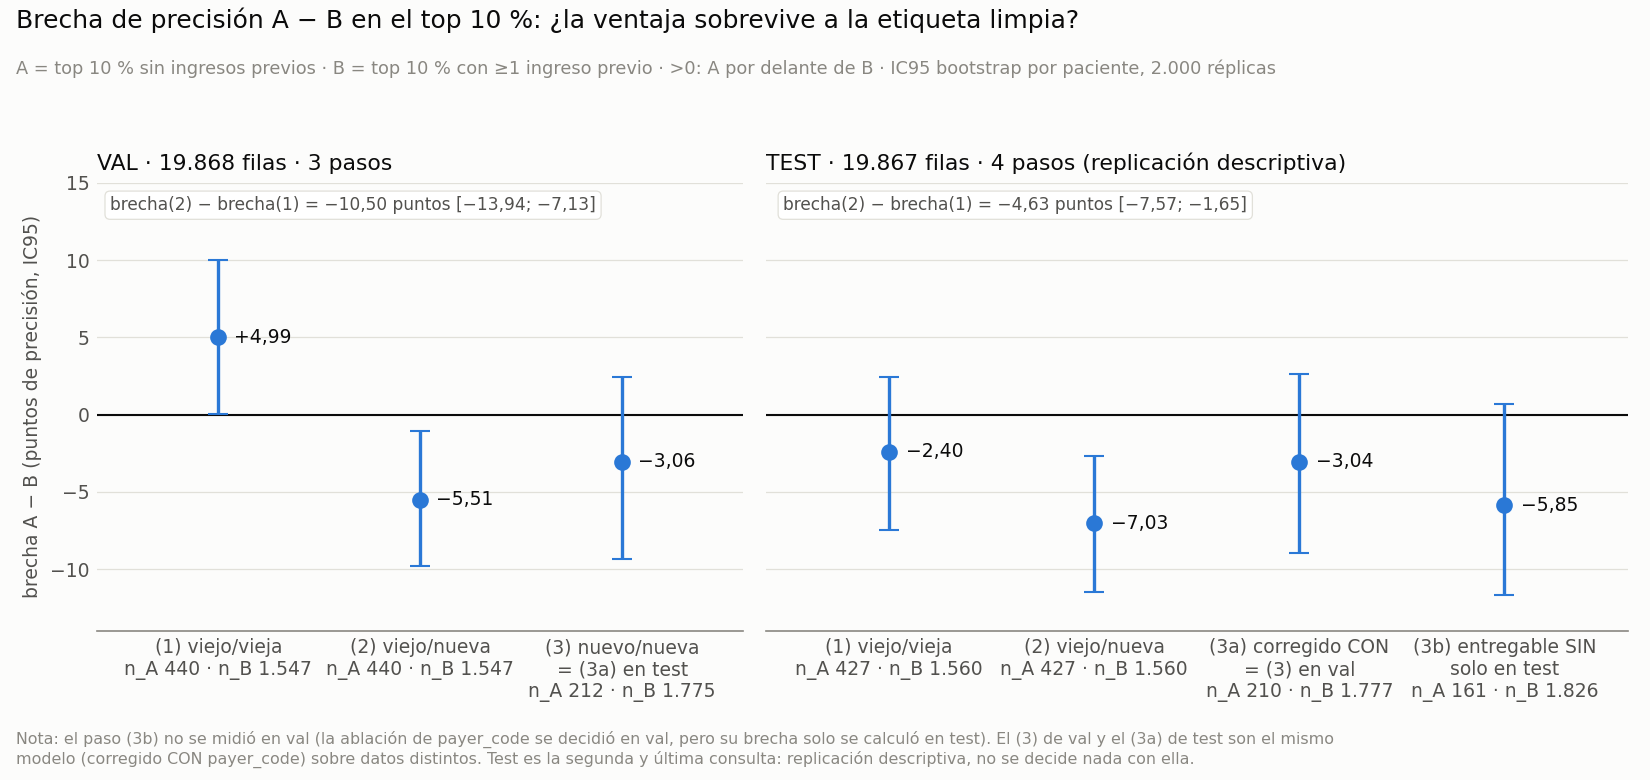

In [10]:
figA = FIG / "phase4_fig_A_brecha_val_test.png"
if figA.exists():
    display(Image(figA, width=980))
else:
    print("Falta la figura A: ejecutar src/phase4_figures.py")

## 8. Equidad: payer_code y la ablación

Quién recibe seguimiento cambia con el target corregido. Medido en val, con el top 10 % y frente a
MC como referencia, el cociente de `Missing` pasa de 1,45 (modelo viejo) a 2,07 (corregido).
`payer_code` es la única variable de seguro que pasa las sondas de ruido en 10/10, así que se
analiza su efecto quitándola.

**Validez y equidad van en sentidos opuestos.** La corrección no baja el rendimiento global (sección 6),
pero sí cambia a quién se le hace seguimiento: en el modelo corregido, SP pasa de 0,83 a 0,39 y
Missing de 1,45 a 2,07 frente a MC. Ese es el conflicto central del trabajo.

La decisión de qué modelo entregar la toma la regla prerregistrada. Aquí solo se describe su
resultado. La recomendación al gestor es suya.

In [11]:
dec = pd.read_csv(REPORTS / "phase4_ablation_decision.csv").iloc[0]
print(f"Fallos robustos en el conjunto común de {dec.grupos_comunes_elegibles} grupos: "
      f"{dec.fallos_robustos_con} -> {dec.fallos_robustos_sin}.")
print(f"Lift medio en CV: {dec.lift_cv_con:.4f} -> {dec.lift_cv_sin:.4f} "
      f"(caída relativa {dec['caida_relativa_%']:.2f} %). Entregable según la regla: {dec.ENTREGABLE}.")

comp = pd.read_csv(REPORTS / "phase4_ablation_composition.csv")
comp.loc[comp["grupo"].isin(["Missing", "SP", "MC"]),
         ["grupo", "n_grupo", "cociente_con", "IC_con_bajo", "IC_con_alto",
          "cociente_sin", "IC_sin_bajo", "IC_sin_alto"]].round(3)

Fallos robustos en el conjunto común de 7 grupos: 2 -> 1.
Lift medio en CV: 1.9878 -> 1.9419 (caída relativa 2.31 %). Entregable según la regla: sin payer_code.


,grupo,n_grupo,cociente_con,IC_con_bajo,IC_con_alto,cociente_sin,IC_sin_bajo,IC_sin_alto
4,MC,6201,1.000,1.000,1.000,1.000,1.000,1.000
6,Missing,7933,2.073,1.753,2.463,0.962,0.829,1.105
8,SP,1075,0.385,0.239,0.568,0.444,0.302,0.597


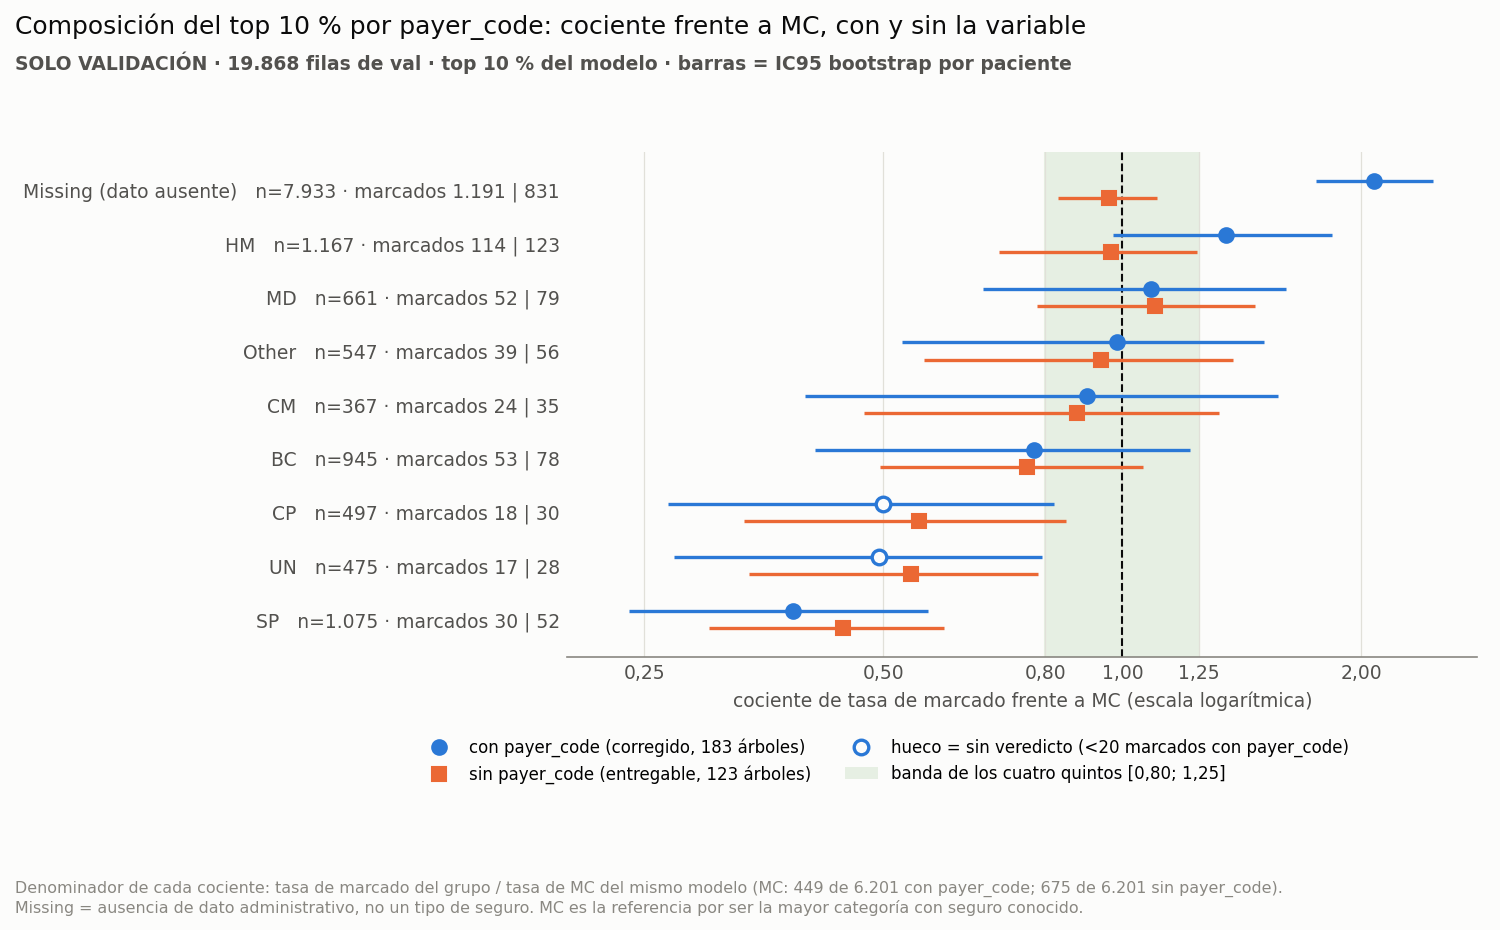

In [12]:
figB = FIG / "phase4_fig_B_payer_code_val.png"
if figB.exists():
    display(Image(figB, width=900))
else:
    print("Falta la figura B: ejecutar src/phase4_figures.py")

In [13]:
fc = pd.read_csv(REPORTS / "phase4_fairness_composition.csv")
fc = fc[(fc["atributo"] == "payer_code") & (fc["top_k"] == "10%")]
print("Cociente frente a MC en el top 10 % de val: modelo viejo frente a corregido (CON payer_code)")
fc.loc[fc["grupo"].isin(["SP", "Missing", "UN", "HM"]),
       ["grupo", "n_grupo", "cociente_modelo_viejo", "cociente", "cociente_IC95_bajo", "cociente_IC95_alto"]].round(3)

Cociente frente a MC en el top 10 % de val: modelo viejo frente a corregido (CON payer_code)


,grupo,n_grupo,cociente_modelo_viejo,cociente,cociente_IC95_bajo,cociente_IC95_alto
13,HM,1167,0.805,1.349,0.973,1.839
16,Missing,7933,1.452,2.073,1.753,2.463
18,SP,1075,0.832,0.385,0.239,0.568
19,UN,475,0.869,0.494,0.272,0.792


**Lectura.** Sin `payer_code`, `Missing` baja de 2,07 a 0,96: el modelo dejaba de leer "no consta el
seguro" como señal de riesgo. Pero `SP` (paciente sin seguro) sigue por debajo de 0,80 (0,44, IC95
[0,30; 0,60]): esa parte sí es recuperable del resto del formulario. El coste en rendimiento es
pequeño pero consistente: el lift medio en CV cae un 2,31 % y el modelo con la variable gana en
5 de 5 folds.

## 9. Test: solo lectura de la consulta única

Test se consultó **una vez**, con el modelo entregable y el target corregido
(`src/phase4_test_final.py`). Aquí solo se leen sus CSV. No se recalcula nada ni se toma ninguna
decisión con ellos. No es comparable con el PR-AUC de 0,227 de la Fase 2, porque el target cambió:
la comparación válida es el lift.

In [14]:
glob_test = pd.read_csv(REPORTS / "phase4_test_global.csv")
topk_test = pd.read_csv(REPORTS / "phase4_test_topk.csv")
pc_test = pd.read_csv(REPORTS / "phase4_test_paired_contrasts.csv")
print("Globales del entregable en test (n = 19.867; prevalencia 9,85 %):")
display(glob_test.round(4))
print("Top-k del entregable en test (precisión sobre marcados; recall sobre positivos):")
display(topk_test.round(4))
print("Contrastes emparejados en test:")
display(pc_test.round(4))

Globales del entregable en test (n = 19.867; prevalencia 9,85 %):


,modelo,n,prevalencia_%,roc_auc,pr_auc,lift_pr_auc,brier
0,ENTREGABLE (sin payer_code),19867,9.8455,0.6655,0.1890,1.9194,0.0855
1,base: prevalencia (constante),19867,9.8455,0.5000,0.0985,1.0000,0.0888
2,base: regla number_inpatient > 0,19867,9.8455,0.5971,0.1246,1.2660,0.3344


Top-k del entregable en test (precisión sobre marcados; recall sobre positivos):


,modelo,top_k,n_marcados,aciertos,precision_%,recall_%,lift
0,ENTREGABLE (sin payer_code),5%,994,267,26.8612,13.6503,2.7283
1,ENTREGABLE (sin payer_code),10%,1987,440,22.1439,22.4949,2.2491
2,ENTREGABLE (sin payer_code),20%,3974,728,18.3191,37.2188,1.8607
3,base: regla number_inpatient > 0,5%,994,140,14.0845,7.1575,1.4306
4,base: regla number_inpatient > 0,10%,1987,294,14.7962,15.0307,1.5028
5,base: regla number_inpatient > 0,20%,3974,607,15.2743,31.0327,1.5514


Contrastes emparejados en test:


,modelo_nuevo,contraste,observado,IC95_bajo,IC95_alto,nulo,excluye_nulo,replicas_usadas,replicas_descartadas
0,(3a) corregido CON payer_code,brecha(2) - brecha(1) [puntos],-4.6266,-7.5737,-1.6545,0.0,True,2000,0
1,(3a) corregido CON payer_code,cociente(2) / cociente(1),0.7772,0.6670,0.8869,1.0,True,2000,0
2,(3a) corregido CON payer_code,delta_A - delta_B [puntos],0.6402,-4.5507,5.6376,0.0,False,2000,0
3,(3b) entregable sin payer_code,brecha(2) - brecha(1) [puntos],-4.6266,-7.5737,-1.6545,0.0,True,2000,0
4,(3b) entregable sin payer_code,cociente(2) / cociente(1),0.7772,0.6670,0.8869,1.0,True,2000,0
5,(3b) entregable sin payer_code,delta_A - delta_B [puntos],3.4454,-2.8967,9.2808,0.0,False,2000,0


Lo que se replica y lo que no:

- **Replica:** el signo y la significación de la inversión de la brecha (paso 2 frente a paso 1),
  aunque con menos de la mitad de la magnitud. Y el mecanismo: el grupo A con destino 22/5 pasa de
  63,93 % a 32,38 % (modelo 3a) y a 35,40 % (entregable), el mismo movimiento que en val.
- **No replica:** la ventaja de A sobre B. En el paso (1) de test el IC95 [−7,45; +2,41] incluye el
  cero, así que A y B no se distinguen. Y el criterio prerregistrado
  `delta_A − delta_B` deja de tener significación en test: los dos intervalos incluyen el cero.
- **Gana a la regla `number_inpatient > 0` en los tres k**, con más margen cuanto más estrecho es
  el seguimiento. Lift en test del entregable: 2,73 (5 %), 2,25 (10 %) y 1,86 (20 %).

## 10. Reflexión crítica: dónde pueden fallar o engañar estas explicaciones

- **Estabilidad no es validez.** El destino 22 es estable entre folds precisamente porque todos
  los folds comparten la misma etiqueta contaminada. Los sanity checks pasan todos sus criterios prerregistrados y no lo detectan. La correlación del
  ranking global bajo etiquetas aleatorias es 0,856 (aviso a partir de 0,7; `xai_sanity_label_randomization.csv`).
- **Una explicación explica la predicción, no el resultado.** En los pares contrastivos las
  probabilidades son casi iguales (0,2617 y 0,2303). SHAP no puede decir quién reingresó.
- **La accionabilidad es limitada.** Para los 6 casos locales elegibles, los contrafactuales salen
  vacíos: el espacio de acciones (fármacos prescritos y destino) no basta. En la población del
  top 10 % fuera de los destinos 22/5, 448 de 1.518 tienen contrafactual, y en 419 de ellos el
  mejor cambio es el destino. Eso refleja la gravedad del paciente (confusión), no una decisión
  libre: "mandarlo a casa" baja la puntuación sin evidencia de que baje el riesgo.
- **Equidad.** La mayor disparidad era la variable, no un proxy, pero `race` es recuperable del
  resto del formulario (AUC OVR macro 0,737). Quitarla no basta para hablar de equidad.
- **Test.** La ventaja sobre la regla simple en el grupo A no sobrevive a datos nuevos. Eso lo
  dice la replicación; el informe no debe presentarla como un hallazgo positivo.

In [15]:
print(f"Avisos de guardarraíles en esta ejecución: {len(AVISOS)}")
for a in AVISOS:
    print(" -", a)
print(f"Tiempo total de ejecución de este notebook: {time.time() - T0:.0f} s")

Avisos de guardarraíles en esta ejecución: 0
Tiempo total de ejecución de este notebook: 80 s
